In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from xgboost import XGBClassifier

In [2]:
df = pd.read_csv("../data/raw/creditcard.csv")

print(df.shape)

(284807, 31)


In [3]:
X = df.drop("Class", axis=1)
y = df["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [4]:
X_train = X_train.copy()
X_test = X_test.copy()

# Time
X_train["TransactionHour"] = (
    (X_train["Time"] // 3600) % 24
)

X_test["TransactionHour"] = (
    (X_test["Time"] // 3600) % 24
)

# Cyclical encoding
X_train["HourSin"] = np.sin(
    2 * np.pi * X_train["TransactionHour"] / 24
)

X_train["HourCos"] = np.cos(
    2 * np.pi * X_train["TransactionHour"] / 24
)

X_test["HourSin"] = np.sin(
    2 * np.pi * X_test["TransactionHour"] / 24
)

X_test["HourCos"] = np.cos(
    2 * np.pi * X_test["TransactionHour"] / 24
)

# Amount
X_train["AmountLog"] = np.log1p(X_train["Amount"])
X_test["AmountLog"] = np.log1p(X_test["Amount"])

# Amount bucket
bins = [-1, 10, 50, 100, 500, 1000, np.inf]

X_train["AmountBucket"] = pd.cut(
    X_train["Amount"],
    bins=bins,
    labels=False
)

X_test["AmountBucket"] = pd.cut(
    X_test["Amount"],
    bins=bins,
    labels=False
)

print(X_train.shape)

(227845, 35)


In [5]:
negative = (y_train == 0).sum()
positive = (y_train == 1).sum()

scale_pos_weight = negative / positive

print(scale_pos_weight)

577.2868020304569


In [6]:
xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    random_state=42,
    eval_metric="logloss",
    n_jobs=-1
)

In [7]:
xgb_model.fit(
    X_train,
    y_train
)

print("Model trained!")

Model trained!


In [8]:
y_prob = xgb_model.predict_proba(X_test)[:, 1]

In [9]:
print(y_prob[:20])

[0.0003253  0.00020176 0.00161344 0.00018097 0.01413651 0.00044021
 0.00021987 0.00026947 0.00134523 0.00013347 0.00286697 0.00441002
 0.00031023 0.00026191 0.00039955 0.00022541 0.00080949 0.00027933
 0.00014866 0.02145123]


In [10]:
threshold = 0.5

y_pred_05 = (
    y_prob >= threshold
).astype(int)

In [11]:
print("Precision:",
      precision_score(y_test, y_pred_05, zero_division=0))

print("Recall:",
      recall_score(y_test, y_pred_05, zero_division=0))

print("F1:",
      f1_score(y_test, y_pred_05, zero_division=0))

Precision: 0.6115107913669064
Recall: 0.8673469387755102
F1: 0.7172995780590717


In [12]:
print("Precision:",
      precision_score(y_test, y_pred_05, zero_division=0))

print("Recall:",
      recall_score(y_test, y_pred_05, zero_division=0))

print("F1:",
      f1_score(y_test, y_pred_05, zero_division=0))

Precision: 0.6115107913669064
Recall: 0.8673469387755102
F1: 0.7172995780590717


In [13]:
thresholds = np.arange(
    0.05,
    0.51,
    0.05
)

In [14]:
results = []

for threshold in thresholds:

    y_pred = (
        y_prob >= threshold
    ).astype(int)

    precision = precision_score(
        y_test,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        y_test,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        y_pred,
        zero_division=0
    )

    results.append({
        "Threshold": threshold,
        "Precision": precision,
        "Recall": recall,
        "F1": f1
    })

In [15]:
threshold_df = pd.DataFrame(results)

threshold_df

,Threshold,Precision,Recall,F1
0,0.05,0.115533,0.918367,0.205245
1,0.10,0.208038,0.897959,0.337812
2,0.15,0.280255,0.897959,0.427184
3,0.20,0.341085,0.897959,0.494382
4,0.25,0.414286,0.887755,0.564935
5,0.30,0.480447,0.877551,0.620939
6,0.35,0.530864,0.877551,0.661538
7,0.40,0.558442,0.877551,0.682540
8,0.45,0.598592,0.867347,0.708333
9,0.50,0.611511,0.867347,0.717300


In [16]:
best_f1_row = threshold_df.loc[
    threshold_df["F1"].idxmax()
]

print(best_f1_row)

Threshold    0.500000
Precision    0.611511
Recall       0.867347
F1           0.717300
Name: 9, dtype: float64


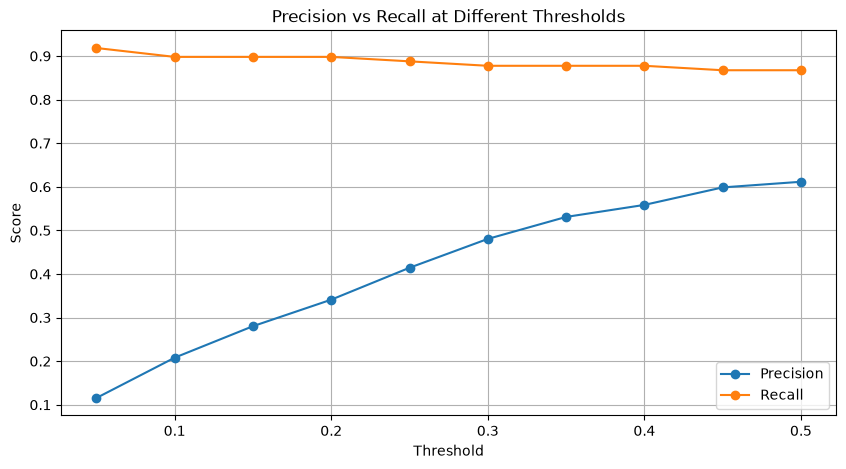

In [17]:
plt.figure(figsize=(10, 5))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    marker="o",
    label="Recall"
)

plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Precision vs Recall at Different Thresholds")

plt.legend()
plt.grid()
plt.show()

In [18]:
optimal_threshold = best_f1_row["Threshold"]

print(
    "Selected threshold:",
    optimal_threshold
)

Selected threshold: 0.5


In [19]:
y_pred_optimal = (
    y_prob >= optimal_threshold
).astype(int)

In [20]:
print(
    "Precision:",
    precision_score(
        y_test,
        y_pred_optimal,
        zero_division=0
    )
)

print(
    "Recall:",
    recall_score(
        y_test,
        y_pred_optimal,
        zero_division=0
    )
)

print(
    "F1:",
    f1_score(
        y_test,
        y_pred_optimal,
        zero_division=0
    )
)

Precision: 0.6115107913669064
Recall: 0.8673469387755102
F1: 0.7172995780590717


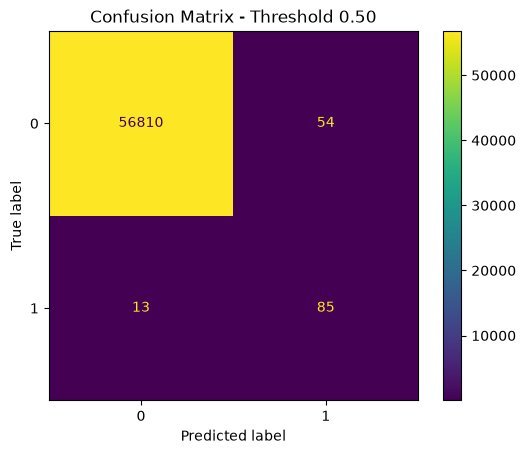

In [21]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_optimal
)

plt.title(
    f"Confusion Matrix - Threshold {optimal_threshold:.2f}"
)

plt.show()

In [22]:
def calculate_risk(probability):

    if probability >= 0.80:
        return "HIGH", "BLOCK"

    elif probability >= 0.50:
        return "MEDIUM", "REVIEW"

    else:
        return "LOW", "ALLOW"

In [24]:
import json

with open("../models/threshold.json", "w") as f:
    json.dump(
        {"threshold": float(optimal_threshold)},
        f,
        indent=4
    )

print("Threshold saved!")

Threshold saved!
